# 09 — Avaliação externa no Ibirapuera e no sistema elétrico brasileiro

Este é o **notebook final** de avaliação do conjunto `generator_model_evaluation`. Os checkpoints Chronos-2 treinados em dados sintéticos recebem as mesmas janelas reais, sem atualização de pesos. O DLinear é treinado separadamente nos anos reais anteriores. Tudo é executado localmente em CPU. O protocolo é nosso; os artigos citados **não** apresentam estes resultados de Chronos-2.

## Fontes científicas e dados

1. **Qualidade do ar, Ibirapuera (São Paulo).** Seguel *et al.* (2022), [*Photochemical sensitivity to emissions and local meteorology in Bogotá, Santiago, and São Paulo*](https://doi.org/10.1525/elementa.2021.00044), *Elementa*, 10(1), 00044. O artigo usa observações de poluição da CETESB para investigar mudanças durante o lockdown, controlando meteorologia e sazonalidade; não define uma tarefa de previsão de 96 horas. Dados da estação, cinco canais horários O3, NO, NO2, CO e PM2.5: [PANGAEA 940276](https://doi.org/10.1594/PANGAEA.940276). Citação BibTeX: `seguel2022photochemical`.
2. **Sistema elétrico brasileiro harmonizado.** Deng *et al.* (2023), [*Harmonized and Open Energy Dataset for Modeling a Highly Renewable Brazilian Power System*](https://doi.org/10.1038/s41597-023-01992-9), *Scientific Data* 10, 103. [Pacote Zenodo v0.2](https://doi.org/10.5281/zenodo.7478165). A base foi proposta para modelagem de sistemas energéticos, não como benchmark de forecasting. Usamos o estado da Bahia e quatro canais: carga elétrica estadual desagregada, potencial eólico onshore, potencial fotovoltaico e afluência hidrelétrica. Os potenciais eólico/solar são perfis modelados por unidade de capacidade, **não geração observada**. A carga estadual também é desagregada de séries regionais, **não medição estadual direta**. Citação BibTeX: `deng2023harmonized`.
3. **Modelo externo sem foundation model.** Zeng *et al.* (2023), [*Are Transformers Effective for Time Series Forecasting?*](https://doi.org/10.1609/aaai.v37i9.26317), AAAI 37(9), 11121–11128. Usamos a arquitetura [DLinear do código dos autores](https://github.com/cure-lab/LTSF-Linear/blob/main/models/DLinear.py): decomposição por média móvel de 25 pontos e duas projeções lineares temporais compartilhadas entre canais (`individual=False`). O tratamento de valores ausentes e a normalização são adaptações deste benchmark. A arquitetura DLinear compartilhada aplica os mapas temporais a cada canal separadamente, sem misturar explicitamente canais; é uma referência não foundation model, não um teste isolado de dependências cruzadas. Citação BibTeX: `zeng2023transformers`.

## Protocolo previamente fixado para esta execução

- Teste zero-shot em **2019**, sem treino, ajuste de hiperparâmetros, normalização global ou seleção de checkpoint com dados reais. Contexto 96 horas; horizonte 96 horas; origens candidatas a cada 24 horas em grade fixa. Avaliamos **todas** as origens elegíveis, sem amostragem de datas.
- Elegibilidade: pelo menos 80% de observações presentes **em cada canal**, separadamente no contexto e no horizonte. A escolha usa somente a máscara de disponibilidade, jamais os valores futuros. Contextos preservam `NaN`, que o Chronos-2 interpreta como dado ausente; predições são pontuadas apenas onde o target foi observado. Nenhuma interpolação do futuro.
- Um grupo Chronos-2 por janela, contendo todos os canais juntos. O Ibirapuera tem 5 canais; a energia, 4. O modelo foi treinado em grupos de 6; avaliar grupos de 5/4 mede também robustez à quantidade de canais. Nenhum skeleton verdadeiro existe nesses dados reais: **não avaliamos a equation head** aqui.
- Resultados por canal em unidades originais e agregados MAE/RMSE. Como as unidades e escalas diferem, **não comparar MAE bruto entre datasets**, nem interpretar a média entre canais como único critério científico. Persistência (último valor observado do contexto) é o controle sem treino.
- Energia: carga e afluência vêm em horário de Brasília (UTC−3); vento e sol em UTC, conforme o artigo. Convertidos a UTC antes da junção. Os 3 primeiros horários UTC de 2019 não têm correspondência nos arquivos anuais locais, resultando em 8.757 horas alinhadas. O recorte é um estudo de caso da Bahia, não inferência para todos os estados.
- Os dois checkpoints LMC (`with`/`without early stopping`) são avaliados como variantes do **mesmo** treino sintético. O modelo do nosso gerador só poderá ser acrescentado quando existir um checkpoint treinado. Outras variantes podem ser passadas em `TSFMXAI_EVAL_MODELS` como JSON `{nome: caminho}` antes de reexecutar; não apresentar uma variante ausente como resultado medido.
- **DLinear supervisionado no domínio real:** treinar com origens de 2014–2017 (ar) e 2012–2017 (energia), validar em 2018, testar em 2019. Nenhum target de treino/validação pode cruzar para o ano seguinte. Normalização ajustada só com treino; ausências no contexto preenchidas apenas com histórico da própria janela e média do treino; loss mascarada em targets ausentes. Adam LR 1e-3, batch 128, até 500 épocas, paciência 20, seed 20261117. São escolhas locais, diferentes dos defaults gerais do script dos autores (10 épocas, batch 32, paciência 3, LR 1e-4); o baseline original não foi publicado para estes dois datasets.
- **Revisão exploratória do protocolo:** execuções iniciais com tetos de 50 e 200 épocas mostraram que a melhor validação da energia ocorria perto dos limites (épocas 50 e 194). Aumentamos o teto para permitir convergência segundo **a validação de 2018**. Como já vimos execuções de teste de 2019, esta análise é exploratória e não deve ser apresentada como benchmark pré-registrado independente. O DLinear recebe dados reais rotulados; o Chronos LMC é **zero-shot**. A comparação causal entre geradores exige o outro Chronos com a mesma arquitetura/protocolo.


## Leitura correta dos erros

**Comparação principal: MAE e WAPE por canal.** Cada canal tem uma unidade e
uma escala próprias. A tabela de MAE por canal abaixo compara modelos apenas
dentro do mesmo canal; a tabela de WAPE apresenta porcentagens por canal.
O resumo prospectivo entre datasets usa o MAE de cada canal dividido pelo
MAE do seasonal naive daquele canal, calculado em
`scripts/evaluate_prior_baselines.py` depois que os dois braços existirem.

`observed_metrics` também calcula um MAE/RMSE agrupando todas as células
observadas. Aqui esses dois valores são guardados somente sob a chave
`diagnostico_agregado_entre_unidades_nao_comparavel` para rastreabilidade
histórica. **Não são um resultado comparativo, não devem ser usados para
ranquear modelos e não entram na conclusão.** Misturam, por exemplo, ppbv,
ppmv e µg/m³ no ar, além de MW e fatores de capacidade na energia.

In [1]:
import hashlib, importlib.metadata, json, os, platform, subprocess, sys, time, urllib.request
from datetime import datetime, timezone
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src/tsfmxai').exists())
sys.path.insert(0, str(ROOT / 'src'))
from tsfmxai.evaluation.real_world import (load_ibirapuera, load_brazil_energy,
    select_windows, last_observed_forecast, observed_metrics, forecast_chronos2,
    concatenate_window_sets)
from tsfmxai.baselines.dlinear import fit_dlinear, predict_dlinear
from chronos.chronos2.model import Chronos2Model

SEED = 20261117
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(min(4, os.cpu_count() or 1))
DATA_DIR = ROOT / 'outputs/real_world_evaluation'
DATA_DIR.mkdir(parents=True, exist_ok=True)
AIR_PATH = DATA_DIR / 'ibirapuera.tsv'
ENERGY_PATH = DATA_DIR / 'brazil_power.zip'
SOURCES = {
  AIR_PATH: 'https://doi.pangaea.de/10.1594/PANGAEA.940276?format=textfile',
  ENERGY_PATH: 'https://zenodo.org/records/7478165/files/Deng_2022_after_revision_Brazilian_power_system_open_data.zip?download=1',
}
for path, url in SOURCES.items():
    if not path.exists():
        urllib.request.urlretrieve(url, path)

BASE = ROOT / 'outputs/chronos2_lmc/lmc-full-12w-mb16-20261116/workers-12'
MODELS = {
  'lmc_without_early_stopping': BASE / 'model_without_early_stopping',
  'lmc_early_stopping': BASE / 'model_early_stopping',
}
MODELS.update({name: Path(path) for name, path in json.loads(os.environ.get('TSFMXAI_EVAL_MODELS', '{}')).items()})
MODELS = {name: path for name, path in MODELS.items() if (path / 'model.safetensors').exists()}
assert MODELS, 'No trained model checkpoints available locally'
print('CPU:', platform.processor(), '| torch:', torch.__version__, '| models:', list(MODELS))

C:\Users\mateu\repos\tsfmxai\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


CPU: Intel64 Family 6 Model 158 Stepping 10, GenuineIntel | torch: 2.12.0+cpu | models: ['lmc_without_early_stopping', 'lmc_early_stopping']


In [2]:
air = load_ibirapuera(AIR_PATH)
energy = load_brazil_energy(ENERGY_PATH, state='BA', year=2019)
DATASETS = {
  'ibirapuera_2019': select_windows(air, year=2019),
  'bahia_energy_2019': select_windows(energy, year=2019),
}
for name, windows in DATASETS.items():
    print(name, 'rows=', len(air if name.startswith('ibirapuera') else energy),
          'eligible=', windows.eligible_count, 'selected=', len(windows.origins),
          'channels=', windows.channels, 'observed target fraction=',
          round(float(np.isfinite(windows.target).mean()), 3))

ibirapuera_2019 rows= 56232 eligible= 255 selected= 255 channels= ('O3 [ppbv]', 'NO [ppbv]', 'NO2 [ppbv]', 'CO [ppmv]', 'PM2.5 [µg/m**3]') observed target fraction= 0.958
bahia_energy_2019 rows= 8757 eligible= 357 selected= 357 channels= ('load_mw', 'wind_capacity_factor', 'solar_capacity_factor', 'hydro_inflow_mwh') observed target fraction= 1.0


In [3]:
RESULTS = {}
PREDICTIONS = {}
for dataset_name, windows in DATASETS.items():
    naive = last_observed_forecast(windows.context, windows.target.shape[1])
    RESULTS[dataset_name] = {'persistence': observed_metrics(naive, windows.target, windows.channels)}
    PREDICTIONS[dataset_name] = {'persistence': naive}

for model_name, model_dir in MODELS.items():
    started = time.perf_counter()
    model = Chronos2Model.from_pretrained(str(model_dir), local_files_only=True).to('cpu').eval()
    for dataset_name, windows in DATASETS.items():
        before = time.perf_counter()
        prediction = forecast_chronos2(model, windows, device='cpu', batch_size=8)
        PREDICTIONS[dataset_name][model_name] = prediction
        result = observed_metrics(prediction, windows.target, windows.channels)
        result['inference_seconds'] = round(time.perf_counter() - before, 3)
        RESULTS[dataset_name][model_name] = result
        print(dataset_name, model_name,
              'MAE_por_canal=', {channel: round(row['mae'], 4)
                                  for channel, row in result['per_channel'].items()},
              'seconds=', result['inference_seconds'], flush=True)
    del model
print('Chronos evaluation complete.')

# Supervised reference from Zeng et al.; real-data train/validation years never include test 2019.
TRAIN_SETS = {
  'ibirapuera_2019': concatenate_window_sets([select_windows(air, year=y) for y in range(2014, 2018)]),
  'bahia_energy_2019': concatenate_window_sets([
      select_windows(load_brazil_energy(ENERGY_PATH, state='BA', year=y), year=y)
      for y in range(2012, 2018)]),
}
VALID_SETS = {
  'ibirapuera_2019': select_windows(air, year=2018),
  'bahia_energy_2019': select_windows(load_brazil_energy(ENERGY_PATH, state='BA', year=2018), year=2018),
}
DLINEAR_FITS = {}
for dataset_name, windows in DATASETS.items():
    started = time.perf_counter()
    fit = fit_dlinear(TRAIN_SETS[dataset_name], VALID_SETS[dataset_name],
                      seed=SEED, epochs=500, batch_size=128, learning_rate=1e-3, patience=20)
    prediction = predict_dlinear(fit, windows)
    PREDICTIONS[dataset_name]['dlinear_supervised'] = prediction
    score = observed_metrics(prediction, windows.target, windows.channels)
    score['training_and_inference_seconds'] = round(time.perf_counter() - started, 3)
    RESULTS[dataset_name]['dlinear_supervised'] = score
    DLINEAR_FITS[dataset_name] = fit
    print(dataset_name, 'DLinear_supervisionado_MAE_por_canal=',
          {channel: round(row['mae'], 4) for channel, row in score['per_channel'].items()},
          'best_epoch=', fit.best_epoch, 'train_windows=', fit.train_windows,
          'val_windows=', fit.validation_windows, flush=True)
print('All evaluation complete.')

# Conservar o agregado legado só como diagnóstico histórico explicitamente
# rotulado. As tabelas e a conclusão usam exclusivamente métricas por canal.
for dataset_scores in RESULTS.values():
    for model_scores in dataset_scores.values():
        model_scores['diagnostico_agregado_entre_unidades_nao_comparavel'] = {
            'mae': model_scores.pop('mae'),
            'rmse': model_scores.pop('rmse'),
            'interpretacao': 'Nao usar para comparar ou ranquear modelos; mistura unidades.'
        }


ibirapuera_2019 lmc_without_early_stopping MAE_por_canal= {'O3 [ppbv]': 13.012, 'NO [ppbv]': 12.0548, 'NO2 [ppbv]': 8.8027, 'CO [ppmv]': 0.2331, 'PM2.5 [µg/m**3]': 8.2568} seconds= 30.967


bahia_energy_2019 lmc_without_early_stopping MAE_por_canal= {'load_mw': 250.242, 'wind_capacity_factor': 0.0964, 'solar_capacity_factor': 0.0338, 'hydro_inflow_mwh': 119.6153} seconds= 24.225


ibirapuera_2019 lmc_early_stopping MAE_por_canal= {'O3 [ppbv]': 12.353, 'NO [ppbv]': 10.1432, 'NO2 [ppbv]': 8.135, 'CO [ppmv]': 0.22, 'PM2.5 [µg/m**3]': 7.7923} seconds= 30.106


bahia_energy_2019 lmc_early_stopping MAE_por_canal= {'load_mw': 229.9932, 'wind_capacity_factor': 0.0947, 'solar_capacity_factor': 0.0366, 'hydro_inflow_mwh': 118.7217} seconds= 24.243


Chronos evaluation complete.


ibirapuera_2019 DLinear_supervisionado_MAE_por_canal= {'O3 [ppbv]': 10.2604, 'NO [ppbv]': 8.5991, 'NO2 [ppbv]': 7.1457, 'CO [ppmv]': 0.1796, 'PM2.5 [µg/m**3]': 7.6456} best_epoch= 48 train_windows= 651 val_windows= 224


bahia_energy_2019 DLinear_supervisionado_MAE_por_canal= {'load_mw': 108.1513, 'wind_capacity_factor': 0.0792, 'solar_capacity_factor': 0.0275, 'hydro_inflow_mwh': 215.2351} best_epoch= 296 train_windows= 2144 val_windows= 357


All evaluation complete.


ibirapuera_2019: MAE por canal (unidade original)


channel,O3 [ppbv],NO [ppbv],NO2 [ppbv],CO [ppmv],PM2.5 [µg/m**3]
model,,,,,
dlinear_supervised,10.2604,8.5991,7.1457,0.1796,7.6456
lmc_early_stopping,12.3530,10.1432,8.1350,0.2200,7.7923
lmc_without_early_stopping,13.0120,12.0548,8.8027,0.2331,8.2568
persistence,16.2164,12.9306,11.7579,0.3162,8.9186


ibirapuera_2019: WAPE por canal (%)


channel,O3 [ppbv],NO [ppbv],NO2 [ppbv],CO [ppmv],PM2.5 [µg/m**3]
model,,,,,
dlinear_supervised,47.2167,119.1559,49.1666,47.4201,59.6608
lmc_early_stopping,56.8464,140.5527,55.9734,58.0858,60.8055
lmc_without_early_stopping,59.8794,167.0412,60.5678,61.5514,64.4306
persistence,74.6253,179.1779,80.9011,83.4835,69.5949


bahia_energy_2019: MAE por canal (unidade original)


channel,load_mw,wind_capacity_factor,solar_capacity_factor,hydro_inflow_mwh
model,,,,
dlinear_supervised,108.1513,0.0792,0.0275,215.2351
lmc_early_stopping,229.9932,0.0947,0.0366,118.7217
lmc_without_early_stopping,250.2420,0.0964,0.0338,119.6153
persistence,264.8814,0.0961,0.1816,133.2286


bahia_energy_2019: WAPE por canal (%)


channel,load_mw,wind_capacity_factor,solar_capacity_factor,hydro_inflow_mwh
model,,,,
dlinear_supervised,3.3501,36.3814,15.1264,12.9973
lmc_early_stopping,7.1242,43.5269,20.1574,7.1692
lmc_without_early_stopping,7.7514,44.3004,18.6221,7.2231
persistence,8.2049,44.1823,100.0000,8.0452


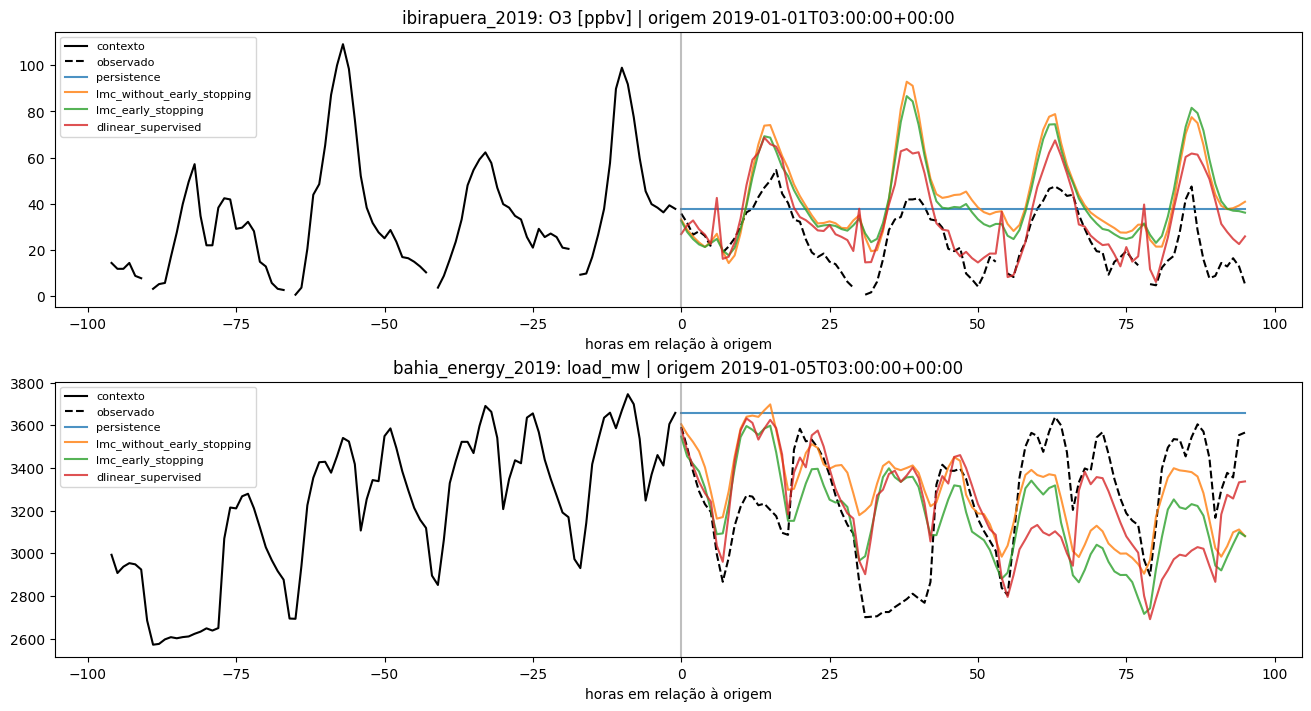

In [4]:
for dataset_name, windows in DATASETS.items():
    rows = []
    for model_name, result in RESULTS[dataset_name].items():
        for channel, score in result['per_channel'].items():
            rows.append({'model': model_name, 'channel': channel, **score})
    scores = pd.DataFrame(rows)
    for metric, title in [('mae', 'MAE por canal (unidade original)'),
                          ('wape_percent', 'WAPE por canal (%)')]:
        print(f'{dataset_name}: {title}')
        display(scores.pivot(index='model', columns='channel', values=metric)
                      .reindex(columns=windows.channels).round(4))

fig, axes = plt.subplots(2, 1, figsize=(13, 7), constrained_layout=True)
for ax, (dataset_name, windows) in zip(axes, DATASETS.items()):
    channel = 0
    start = np.arange(-windows.context.shape[1], 0)
    future = np.arange(windows.target.shape[1])
    ax.plot(start, windows.context[0, :, channel], label='contexto', color='black')
    ax.plot(future, windows.target[0, :, channel], label='observado', color='black', linestyle='--')
    for model_name, prediction in PREDICTIONS[dataset_name].items():
        ax.plot(future, prediction[0, :, channel], label=model_name, alpha=.8)
    ax.axvline(0, color='gray', alpha=.5)
    ax.set_title(f'{dataset_name}: {windows.channels[channel]} | origem {windows.origins[0]}')
    ax.set_xlabel('horas em relação à origem')
    ax.legend(fontsize=8)
plt.show()

In [5]:
# REGISTRO COMPLETO DO EXPERIMENTO — uma única célula: configuração,
# proveniência, seeds, métricas, síntese científica e reprodução.
def sha256(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as handle:
        for block in iter(lambda: handle.read(8 * 1024 * 1024), b''):
            digest.update(block)
    return digest.hexdigest()

def package_version(name):
    try: return importlib.metadata.version(name)
    except importlib.metadata.PackageNotFoundError: return None

relative_skill = {}
vs_dlinear = {}
for dataset_name, scores in RESULTS.items():
    baseline = scores['persistence']['per_channel']
    relative_skill[dataset_name] = {}
    for model_name, score in scores.items():
        if model_name == 'persistence':
            continue
        by_channel = {channel: 1 - row['mae'] / baseline[channel]['mae']
                      for channel, row in score['per_channel'].items()}
        relative_skill[dataset_name][model_name] = {
            'mae_skill_vs_persistence_per_channel': by_channel,
            'mean_channel_skill': float(np.mean(list(by_channel.values()))),
            'channels_better_than_persistence': sum(value > 0 for value in by_channel.values()),
        }
    reference = scores['dlinear_supervised']['per_channel']
    vs_dlinear[dataset_name] = {}
    for model_name, score in scores.items():
        if model_name in ('persistence', 'dlinear_supervised'):
            continue
        by_channel = {channel: 1 - row['mae'] / reference[channel]['mae']
                      for channel, row in score['per_channel'].items()}
        vs_dlinear[dataset_name][model_name] = {
            'mae_skill_vs_dlinear_per_channel': by_channel,
            'mean_channel_skill': float(np.mean(list(by_channel.values()))),
            'channels_better_than_dlinear': sum(value > 0 for value in by_channel.values()),
        }

training_result_path = BASE / 'result.json'
training_result = json.loads(training_result_path.read_text(encoding='utf-8')) if training_result_path.exists() else None
record = {
  'executed_utc': datetime.now(timezone.utc).isoformat(),
  'scientific_summary': ('In all eligible daily-grid windows of 2019, the zero-shot LMC Chronos-2 '
      'is compared with a DLinear architecture from Zeng et al. trained on earlier real years. '
      f"The LMC early-stopping checkpoint has lower MAE than DLinear in "
      f"{vs_dlinear['ibirapuera_2019']['lmc_early_stopping']['channels_better_than_dlinear']}/5 air channels and "
      f"{vs_dlinear['bahia_energy_2019']['lmc_early_stopping']['channels_better_than_dlinear']}/4 energy channels. "
      'This is a reference comparison with unequal training data access, not an isolated generator effect. '
      'The own-generator Chronos checkpoint is unavailable locally; no result is imputed. '
      'The source papers did not report this forecasting task and provide no causal/skeleton ground truth.'),
  'citations': {
      'air_paper': 'doi:10.1525/elementa.2021.00044',
      'air_dataset': 'doi:10.1594/PANGAEA.940276',
      'energy_paper': 'doi:10.1038/s41597-023-01992-9',
      'energy_dataset': 'doi:10.5281/zenodo.7478165',
      'dlinear_model_paper': 'doi:10.1609/aaai.v37i9.26317',
  },
  'configuration': {'seed': SEED, 'evaluation_year': 2019, 'energy_state': 'BA',
      'context_hours': 96, 'horizon_hours': 96, 'origin_stride_hours': 24,
      'minimum_observed_fraction_per_channel_per_half': .8,
      'maximum_selected_origins': None, 'selection': 'all eligible daily-grid origins',
      'inference_batch_windows': 8,
      'missing_context': 'NaN passed to Chronos-2', 'missing_future': 'masked in metrics',
      'percentage_error': 'per-channel WAPE = 100 * sum absolute error / sum absolute observed target; undefined for zero denominator',
      'chronos_grouping': 'all channels of each window in one group',
      'checkpoint_selection': 'fixed before real-data evaluation; no fine-tuning'},
  'dlinear_training': {
      'training_years': {'ibirapuera_2019': [2014, 2015, 2016, 2017],
                         'bahia_energy_2019': [2012, 2013, 2014, 2015, 2016, 2017]},
      'validation_year': 2018, 'test_year': 2019,
      'model': 'DLinear shared temporal maps, moving-average kernel 25, authors architecture',
      'local_adaptations': 'train-only per-channel mean/std, past-only forward fill of context, masked target MSE',
      'optimizer': 'Adam', 'learning_rate': 1e-3, 'batch_size': 128,
      'maximum_epochs': 500, 'patience': 20, 'seed': SEED,
      'protocol_revision': ('Exploratory 50/200-epoch runs hit or approached the validation '
                            'ceiling for energy; cap raised after viewing preliminary test results. '
                            'Final checkpoint still selected on 2018 validation only.'),
      'fits': {name: {'best_epoch': fit.best_epoch, 'epochs_run': fit.epochs_run,
                     'validation_normalized_mse': fit.validation_mse,
                     'training_windows': fit.train_windows,
                     'validation_windows': fit.validation_windows,
                     'train_mean': fit.mean.tolist(), 'train_std': fit.scale.tolist(),
                     'weights_sha256': fit.weights_sha256}
               for name, fit in DLINEAR_FITS.items()},
  },
  'provenance': {'git_head': subprocess.check_output(['git', 'rev-parse', 'HEAD'], cwd=ROOT, text=True).strip(),
      'git_dirty': bool(subprocess.check_output(['git', 'status', '--porcelain'], cwd=ROOT, text=True).strip()),
      'air_sha256': sha256(AIR_PATH), 'energy_archive_sha256': sha256(ENERGY_PATH),
      'model_files': {name: {'path': str(path.relative_to(ROOT)),
           'weights_sha256': sha256(path / 'model.safetensors'),
           'config_sha256': sha256(path / 'config.json')} for name, path in MODELS.items()},
      'baseline_training_result_sha256': sha256(training_result_path) if training_result else None,
      'baseline_training_updates': training_result['updates'] if training_result else None,
      'baseline_early_stopping': training_result['early_stopping'] if training_result else None,
      'python': platform.python_version(), 'torch': torch.__version__,
      'pandas': package_version('pandas'), 'numpy': package_version('numpy'),
      'chronos_forecasting': package_version('chronos-forecasting'),
      'device': 'cpu', 'processor': platform.processor(), 'torch_threads': torch.get_num_threads()},
  'datasets': {name: {'available_rows': len(air if name.startswith('ibirapuera') else energy),
      'eligible_origins': w.eligible_count, 'selected_origins': list(w.origins),
      'channels': list(w.channels), 'observed_target_fraction': float(np.isfinite(w.target).mean()),
      'context_missing_fraction': float(np.isnan(w.context).mean())}
      for name, w in DATASETS.items()},
  'metrics': RESULTS,
  'relative_mae_skill_vs_persistence': relative_skill,
  'relative_mae_skill_vs_dlinear': vs_dlinear,
  'reproduction': ('From repository root with Python 3.11 and CPU-capable Chronos-2 environment: '
      'python -m nbconvert --to notebook --execute --inplace '
      'experiments/generator_model_evaluation/09_real_world_brazil_evaluation.ipynb. '
      'The notebook downloads PANGAEA 940276 and Zenodo 7478165 to ignored outputs/ if absent; '
      'place trained model directories locally or set TSFMXAI_EVAL_MODELS JSON before execution.'),
}
print(json.dumps(record, ensure_ascii=False, indent=2, default=str))

{
  "executed_utc": "2026-11-18T19:15:32.130734+00:00",
  "scientific_summary": "In all eligible daily-grid windows of 2019, the zero-shot LMC Chronos-2 is compared with a DLinear architecture from Zeng et al. trained on earlier real years. The LMC early-stopping checkpoint has lower MAE than DLinear in 0/5 air channels and 1/4 energy channels. This is a reference comparison with unequal training data access, not an isolated generator effect. The own-generator Chronos checkpoint is unavailable locally; no result is imputed. The source papers did not report this forecasting task and provide no causal/skeleton ground truth.",
  "citations": {
    "air_paper": "doi:10.1525/elementa.2021.00044",
    "air_dataset": "doi:10.1594/PANGAEA.940276",
    "energy_paper": "doi:10.1038/s41597-023-01992-9",
    "energy_dataset": "doi:10.5281/zenodo.7478165",
    "dlinear_model_paper": "doi:10.1609/aaai.v37i9.26317"
  },
  "configuration": {
    "seed": 20261117,
    "evaluation_year": 2019,
    "ener